# SberAutoSubscription. Part 1: EDA

Data: `ga_sessions.csv` (one row per visit) and `ga_hits.csv` (one row per event inside a visit, about 4 GB). Target: the visit has at least one of the target event_action values from the guide.

## 1. Loading the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

In [2]:
sessions = pd.read_csv('data/ga_sessions.csv', low_memory=False)
print(sessions.shape)
sessions.head()

(1860042, 18)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow


In [3]:
sessions.info()

<class 'pandas.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 18 columns):
 #   Column                    Dtype
---  ------                    -----
 0   session_id                str  
 1   client_id                 str  
 2   visit_date                str  
 3   visit_time                str  
 4   visit_number              int64
 5   utm_source                str  
 6   utm_medium                str  
 7   utm_campaign              str  
 8   utm_adcontent             str  
 9   utm_keyword               str  
 10  device_category           str  
 11  device_os                 str  
 12  device_brand              str  
 13  device_model              str  
 14  device_screen_resolution  str  
 15  device_browser            str  
 16  geo_country               str  
 17  geo_city                  str  
dtypes: int64(1), str(17)
memory usage: 255.4 MB


### ga_hits

4 GB is too much to load at once, so I read it in chunks of 2 million rows and count what I need on the way.

In [4]:
pd.read_csv('data/ga_hits.csv', nrows=5)

,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,NaN
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,NaN
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,NaN
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,NaN
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,NaN


In [5]:
target_actions = ['sub_car_claim_click', 'sub_car_claim_submit_click', 'sub_open_dialog_click',
                  'sub_custom_question_submit_click', 'sub_call_number_click', 'sub_callback_submit_click',
                  'sub_submit_success', 'sub_car_request_submit_click']

n_rows = 0
nulls = None
hit_types = pd.Series(dtype='int64')
event_categories = pd.Series(dtype='int64')
target_action_counts = pd.Series(dtype='int64')
hits_per_day = pd.Series(dtype='int64')
hits_per_session = []
target_sessions = set()

for chunk in pd.read_csv('data/ga_hits.csv', chunksize=2_000_000, low_memory=False):
    n_rows += len(chunk)
    nulls = chunk.isna().sum() if nulls is None else nulls + chunk.isna().sum()
    hit_types = hit_types.add(chunk['hit_type'].value_counts(), fill_value=0)
    event_categories = event_categories.add(chunk['event_category'].value_counts(), fill_value=0)
    hits_per_day = hits_per_day.add(chunk['hit_date'].value_counts(), fill_value=0)
    hits_per_session.append(chunk.groupby('session_id').size())

    is_target = chunk['event_action'].isin(target_actions)
    target_action_counts = target_action_counts.add(chunk.loc[is_target, 'event_action'].value_counts(), fill_value=0)
    target_sessions.update(chunk.loc[is_target, 'session_id'].unique())

# one visit can be split between two neighbouring chunks, so sum again
hits_per_session = pd.concat(hits_per_session).groupby(level=0).sum()
print('Events:', n_rows)
print('Visits with events:', len(hits_per_session))
print('Visits with a target action:', len(target_sessions))

Events: 15726470
Visits with events: 1734610
Visits with a target action: 50760


In [6]:
print('Missing values in ga_hits, %:')
(nulls / n_rows * 100).round(1).sort_values(ascending=False)

Missing values in ga_hits, %:


event_value       100.0
hit_time           58.2
hit_referer        39.9
event_label        23.9
session_id          0.0
hit_date            0.0
hit_number          0.0
hit_type            0.0
hit_page_path       0.0
event_category      0.0
event_action        0.0
dtype: float64

In [7]:
print(hit_types.astype(int))
print()
print(event_categories.sort_values(ascending=False).head(10).astype(int))

hit_type
event    15726470
dtype: int64

event_category
card_web            7456998
search_form         2423605
sub_page_view       1986074
sub_button_click    1073471
listing_ads         1040468
cars                 358915
sap_search_form      356596
quiz                 263134
auth                 189373
sap_search__form     188129
dtype: int64


In [8]:
target_action_counts.sort_values(ascending=False).astype(int)

event_action
sub_car_claim_click                 37928
sub_open_dialog_click               25870
sub_submit_success                  18439
sub_car_claim_submit_click          12359
sub_call_number_click                3653
sub_callback_submit_click            3074
sub_car_request_submit_click         2966
sub_custom_question_submit_click      619
dtype: int64

15.7 million events in 1,734,610 visits. event_value is empty everywhere, hit_time in 58%, hit_referer in 40%, but session_id and event_action (the only columns I need) have no gaps. hit_type is always event. The most frequent target actions are sub_car_claim_click (37,928) and sub_open_dialog_click (25,870).

## 2. Target variable and joining the tables

In [9]:
target = pd.DataFrame({'session_id': hits_per_session.index,
                       'hits_count': hits_per_session.values})
target['target'] = target['session_id'].isin(target_sessions).astype(int)
target.to_csv('data/target.csv', index=False)

print('Visits in ga_sessions:', sessions['session_id'].nunique())
print('Visits in ga_hits:', target['session_id'].nunique())
print('In sessions but not in hits:', (~sessions['session_id'].isin(target['session_id'])).sum())
print('Target visits missing from sessions:', len(target_sessions - set(sessions['session_id'])))

Visits in ga_sessions: 1860042


Visits in ga_hits: 1734610
In sessions but not in hits: 127776


Target visits missing from sessions: 446


127,776 visits have no events, so their target is unknown. I don't set them to 0, I just use an inner join. 446 target visits exist only in hits and can't be used without the session info.

In [10]:
df = sessions.merge(target, on='session_id', how='inner')
print(df.shape)
print('Share of visits with a target action:', round(df['target'].mean(), 4))

(1732266, 20)
Share of visits with a target action: 0.029


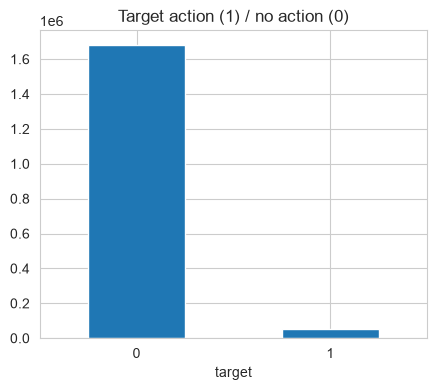

In [11]:
plt.figure(figsize=(5, 4))
df['target'].value_counts().plot(kind='bar')
plt.title('Target action (1) / no action (0)')
plt.xticks(rotation=0)
plt.show()

## 3. Cleaning

In [12]:
print('Duplicated session_id:', df['session_id'].duplicated().sum())
print('Fully duplicated rows:', df.duplicated().sum())

Duplicated session_id: 0


Fully duplicated rows: 0


In [13]:
# '(not set)' is also a missing value, just written as a string
obj_cols = df.select_dtypes(include='object').columns.tolist() + df.select_dtypes(include='string').columns.tolist()
for col in obj_cols:
    df[col] = df[col].replace('(not set)', np.nan)

missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing[missing > 0]

device_model     99.1
utm_keyword      58.9
device_os        58.6
device_brand     21.0
utm_adcontent    17.6
utm_campaign     11.3
geo_city          4.2
geo_country       0.1
dtype: float64

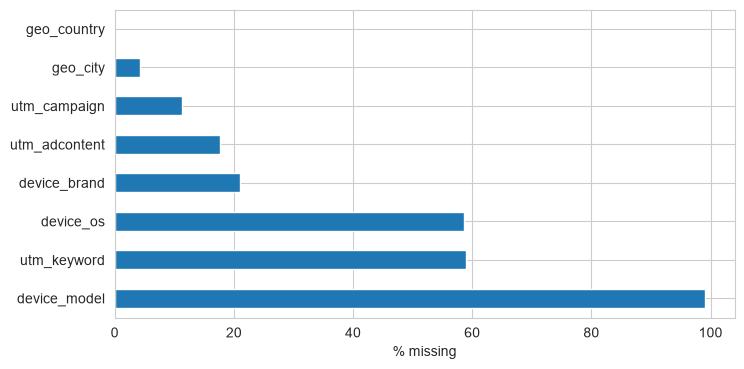

In [14]:
plt.figure(figsize=(8, 4))
missing[missing > 0].plot(kind='barh')
plt.xlabel('% missing')
plt.show()

Missing values: device_model (99% empty) is dropped. device_os is restored from the brand where possible (Apple = iOS, other phones and tablets = Android). The other gaps (utm_keyword, device_brand of desktops, utm_adcontent, utm_campaign, geo) are filled with 'other'.

In [15]:
# device_model is almost empty, drop it; client_id is not needed for the model, but I keep it to look at repeat visits
df = df.drop(columns=['device_model'])

# device_os can be partly restored from the brand and device type
df.loc[df['device_os'].isna() & (df['device_brand'] == 'Apple'), 'device_os'] = 'iOS'
df.loc[df['device_os'].isna() & df['device_brand'].notna() & (df['device_brand'] != 'Apple')
       & df['device_category'].isin(['mobile', 'tablet']), 'device_os'] = 'Android'

# desktops almost never have a brand
print(df.groupby('device_category')['device_brand'].apply(lambda x: x.isna().mean()).round(3))

device_category
desktop    1.000
mobile     0.012
tablet     0.015
Name: device_brand, dtype: float64


In [16]:
cat_cols = ['utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
            'device_category', 'device_os', 'device_brand', 'device_screen_resolution', 'device_browser',
            'geo_country', 'geo_city']
df[cat_cols] = df[cat_cols].fillna('other')
print('Missing values left:', df[cat_cols].isna().sum().sum())
df['device_os'].value_counts().head(8)

Missing values left: 0


device_os
Android       874072
iOS           503538
other         244780
Windows        81740
Macintosh      23415
Linux           4616
Chrome OS         65
BlackBerry        24
Name: count, dtype: int64

In [17]:
# data types
df['visit_date'] = pd.to_datetime(df['visit_date'])
df['visit_hour'] = pd.to_datetime(df['visit_time'], format='%H:%M:%S').dt.hour
df['visit_weekday'] = df['visit_date'].dt.dayofweek   # 0 = Monday

# screen resolution -> width and height
res = df['device_screen_resolution'].str.split('x', expand=True)
df['screen_width'] = pd.to_numeric(res[0], errors='coerce')
df['screen_height'] = pd.to_numeric(res[1], errors='coerce')
print(df[['screen_width', 'screen_height']].describe().round(0))

       screen_width  screen_height
count     1732266.0      1732266.0
mean          659.0          839.0
std           555.0          188.0
min             0.0            0.0
25%           360.0          760.0
50%           393.0          844.0
75%           428.0          896.0
max          5924.0        20000.0


In [18]:
# resolutions like 0x0 or huge ones are treated as errors
bad_screen = (df['screen_width'] < 100) | (df['screen_height'] < 100) | (df['screen_width'] > 8000) | (df['screen_height'] > 8000)
print('Strange resolutions:', bad_screen.sum())
df.loc[bad_screen, ['screen_width', 'screen_height']] = np.nan
df['screen_width'] = df['screen_width'].fillna(df['screen_width'].median())
df['screen_height'] = df['screen_height'].fillna(df['screen_height'].median())

Strange resolutions: 37


## 4. Distributions and the link with the target action

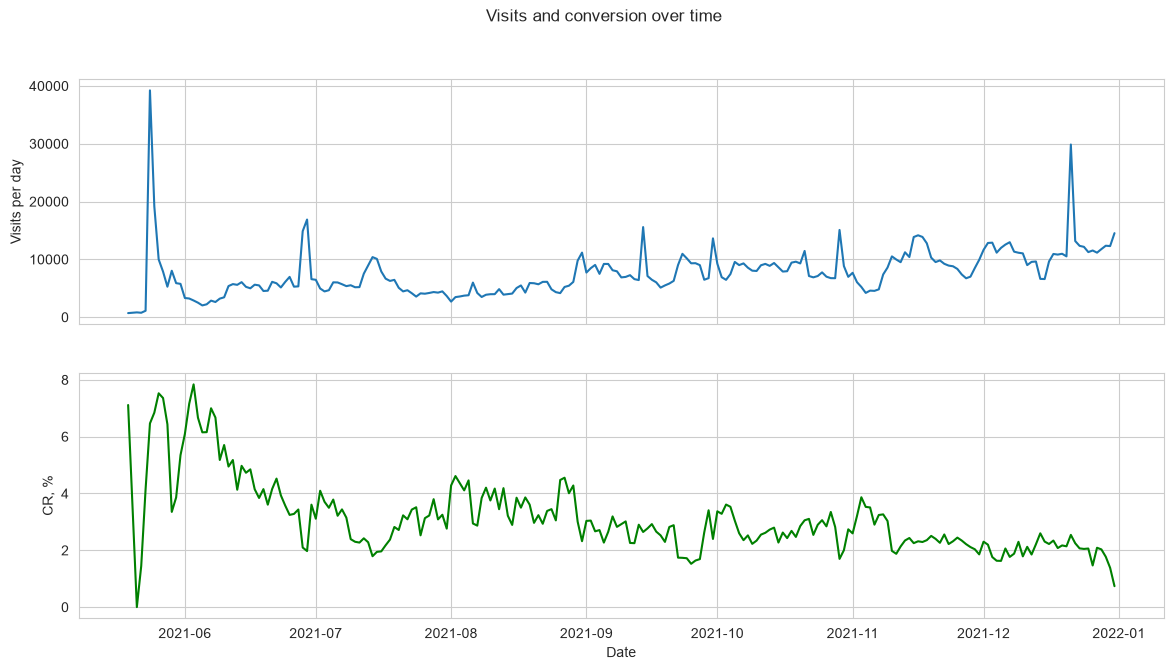

In [19]:
daily = df.groupby('visit_date').agg(visits=('session_id', 'size'), cr=('target', 'mean'))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(daily.index, daily['visits'])
axes[0].set_ylabel('Visits per day')
axes[1].plot(daily.index, daily['cr'] * 100, color='green')
axes[1].set_ylabel('CR, %')
axes[1].set_xlabel('Date')
plt.suptitle('Visits and conversion over time')
plt.show()

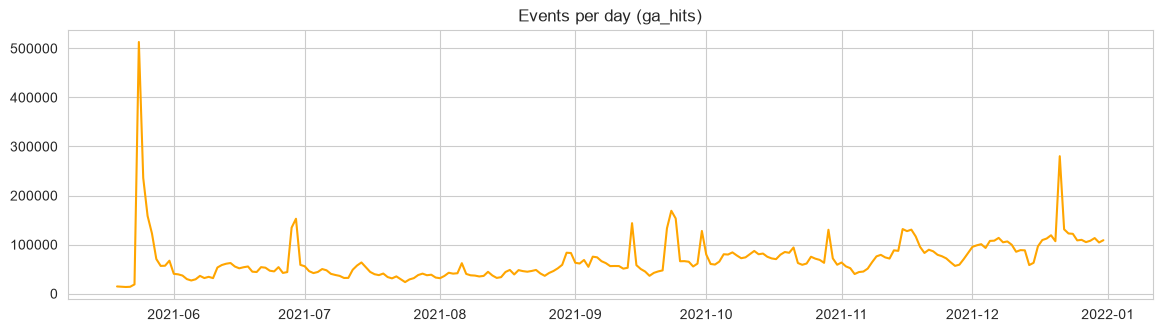

In [20]:
hits_daily = hits_per_day.copy()
hits_daily.index = pd.to_datetime(hits_daily.index)
hits_daily = hits_daily.sort_index()

plt.figure(figsize=(14, 3.5))
plt.plot(hits_daily.index, hits_daily.values, color='orange')
plt.title('Events per day (ga_hits)')
plt.show()

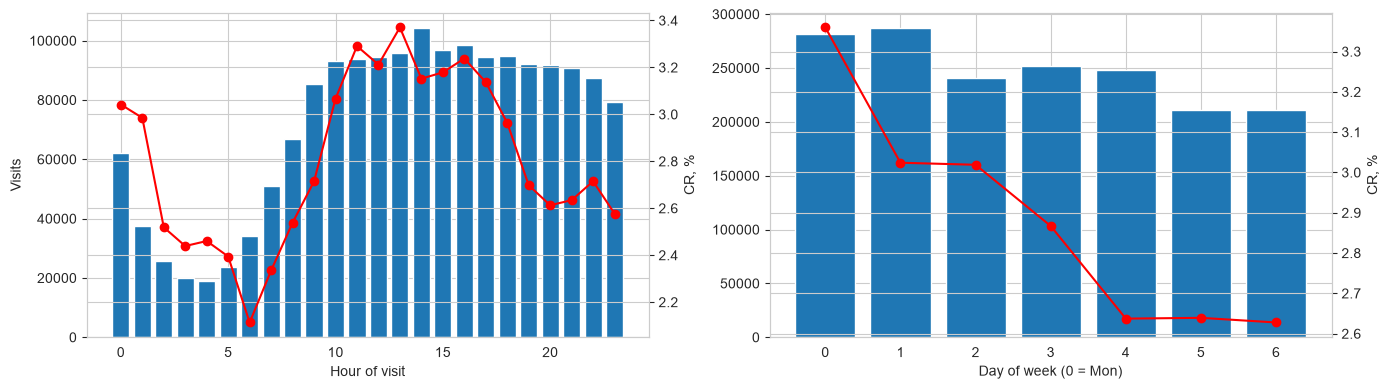

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_hour = df.groupby('visit_hour')['target'].agg(['size', 'mean'])
axes[0].bar(by_hour.index, by_hour['size'])
axes[0].set_xlabel('Hour of visit')
axes[0].set_ylabel('Visits')
ax2 = axes[0].twinx()
ax2.plot(by_hour.index, by_hour['mean'] * 100, color='red', marker='o')
ax2.set_ylabel('CR, %')

by_wd = df.groupby('visit_weekday')['target'].agg(['size', 'mean'])
axes[1].bar(by_wd.index, by_wd['size'])
axes[1].set_xlabel('Day of week (0 = Mon)')
ax3 = axes[1].twinx()
ax3.plot(by_wd.index, by_wd['mean'] * 100, color='red', marker='o')
ax3.set_ylabel('CR, %')
plt.tight_layout()
plt.show()

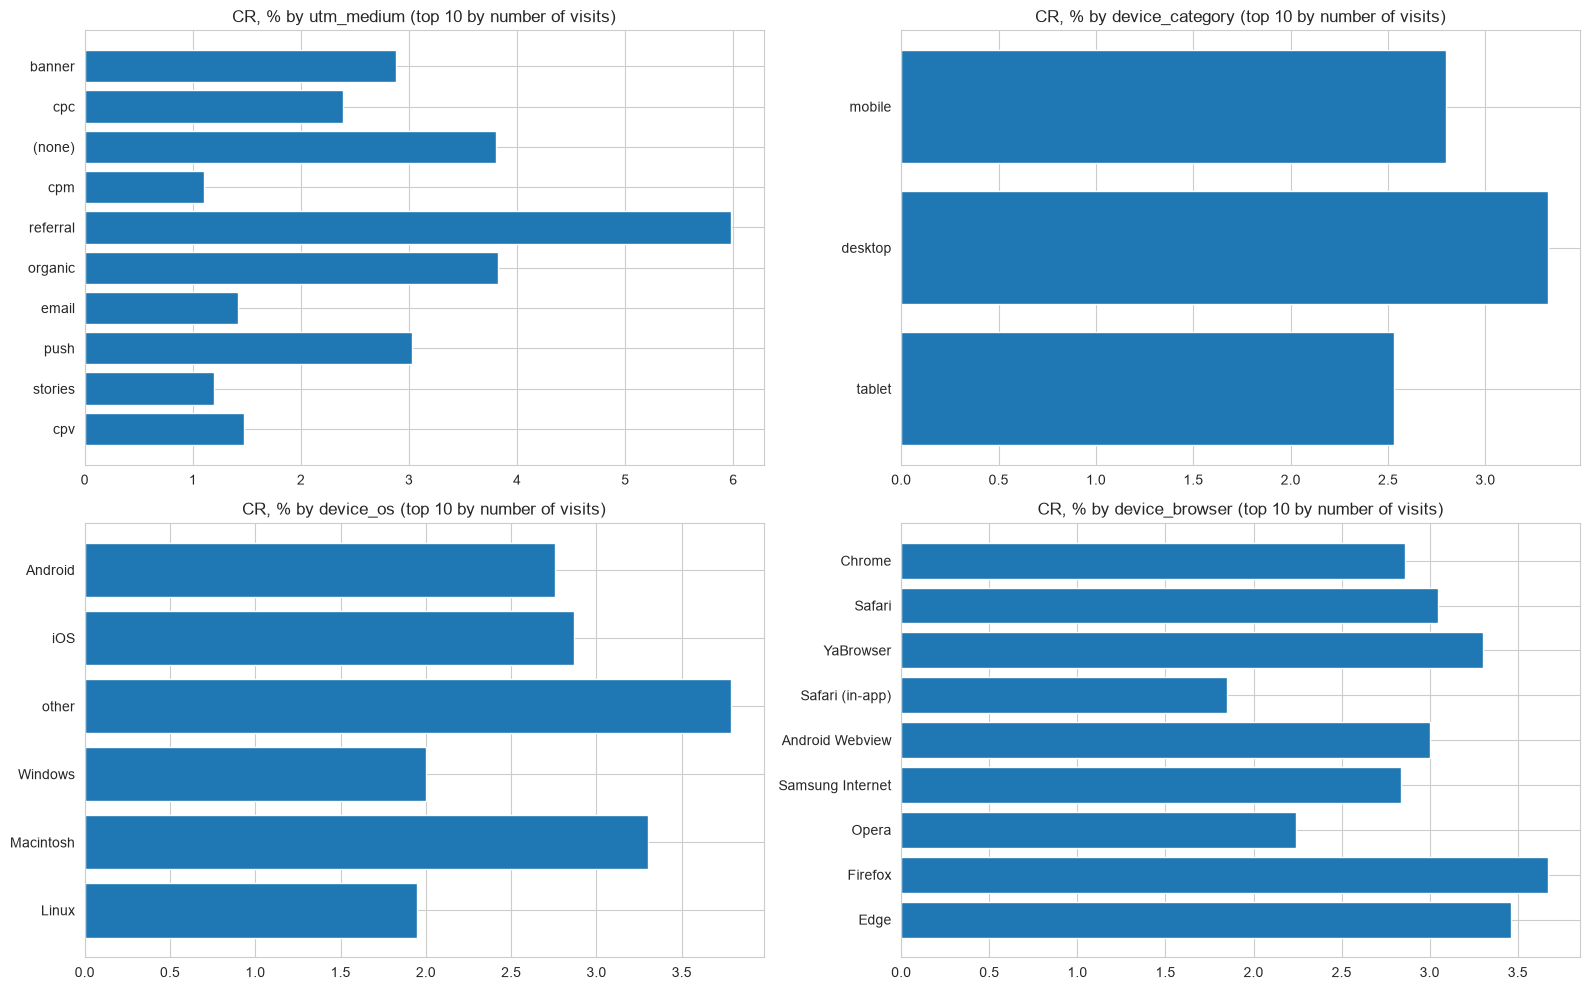

In [22]:
def cr_by(col, top=10, min_visits=1000):
    t = df.groupby(col)['target'].agg(visits='size', cr='mean')
    t = t[t['visits'] >= min_visits].sort_values('visits', ascending=False).head(top)
    t['cr'] = (t['cr'] * 100).round(2)
    return t


fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col in zip(axes.flatten(), ['utm_medium', 'device_category', 'device_os', 'device_browser']):
    t = cr_by(col, top=10)
    ax.barh(t.index.astype(str)[::-1], t['cr'][::-1])
    ax.set_title(f'CR, % by {col} (top 10 by number of visits)')
plt.tight_layout()
plt.show()

In [23]:
cr_by('utm_medium', top=10)

,visits,cr
utm_medium,,
banner,525206,2.88
cpc,399395,2.39
(none),277060,3.80
cpm,229791,1.10
referral,136851,5.98
organic,55009,3.82
email,28287,1.42
push,27710,3.03
stories,10472,1.20


In [24]:
# social media sources and the two capitals (lists from the project guide)
social = ['QxAxdyPLuQMEcrdZWdWb', 'MvfHsxITijuriZxsqZqt', 'ISrKoXQCxqqYvAZICvjs',
          'IZEXUFLARCUMynmHNBGo', 'PlbkrSYoHuZBWfYjYnfw', 'gVRrcxiDQubJiljoTbGm']
df['is_social'] = df['utm_source'].isin(social).astype(int)
df['is_organic'] = df['utm_medium'].isin(['organic', 'referral', '(none)']).astype(int)
df['is_moscow_spb'] = df['geo_city'].isin(['Moscow', 'Saint Petersburg']).astype(int)
df['is_russia'] = (df['geo_country'] == 'Russia').astype(int)

for col in ['is_organic', 'is_social', 'is_moscow_spb', 'is_russia']:
    t = df.groupby(col)['target'].agg(visits='size', cr='mean')
    t['cr'] = (t['cr'] * 100).round(2)
    print(col)
    print(t)
    print()

is_organic
             visits    cr
is_organic               
0           1263346  2.34
1            468920  4.44

is_social
            visits    cr
is_social               
0          1475986  3.14
1           256280  1.57

is_moscow_spb
                visits    cr
is_moscow_spb               
0               702936  2.78
1              1029330  2.99

is_russia
            visits    cr
is_russia               
0            49843  2.32
1          1682423  2.92



In [25]:
cr_by('geo_city', top=10)

,visits,cr
geo_city,,
Moscow,750928,3.15
Saint Petersburg,278402,2.55
other,73297,2.17
Yekaterinburg,33555,2.64
Krasnodar,30260,3.57
Kazan,27689,4.11
Samara,23433,3.10
Nizhny Novgorod,20782,2.69
Ufa,20283,3.15


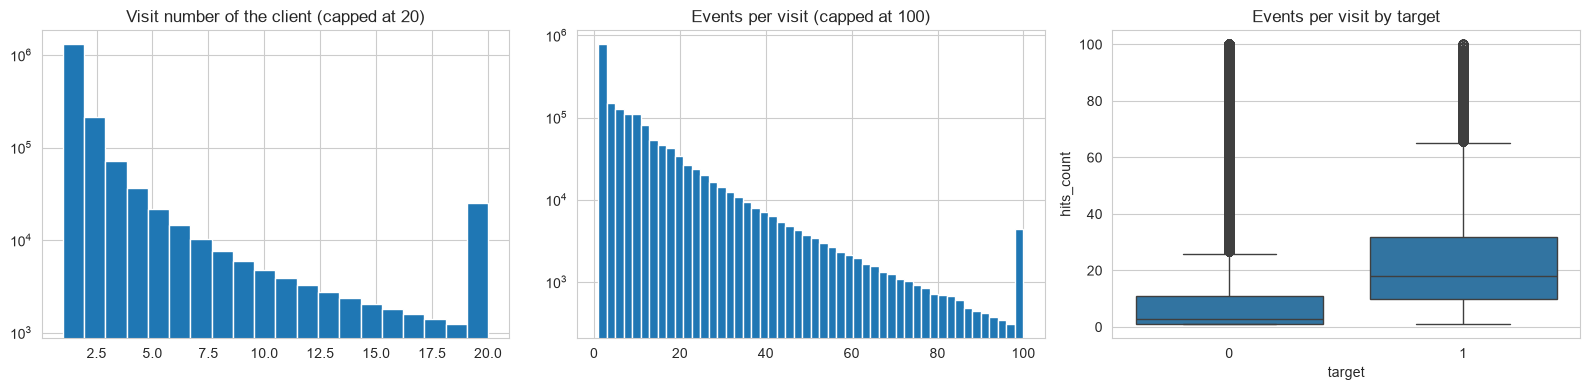

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(df['visit_number'].clip(upper=20), bins=20)
axes[0].set_title('Visit number of the client (capped at 20)')
axes[0].set_yscale('log')

axes[1].hist(df['hits_count'].clip(upper=100), bins=50)
axes[1].set_title('Events per visit (capped at 100)')
axes[1].set_yscale('log')

sns.boxplot(x='target', y='hits_count', data=df[df['hits_count'] <= 100], ax=axes[2])
axes[2].set_title('Events per visit by target')
plt.tight_layout()
plt.show()

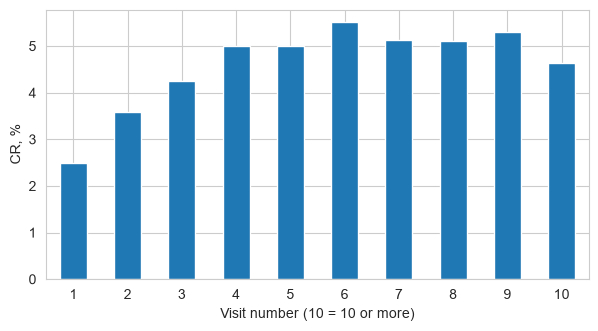

In [27]:
cr_visit_number = df.groupby(df['visit_number'].clip(upper=10))['target'].mean() * 100
plt.figure(figsize=(7, 3.5))
cr_visit_number.plot(kind='bar')
plt.xlabel('Visit number (10 = 10 or more)')
plt.ylabel('CR, %')
plt.xticks(rotation=0)
plt.show()

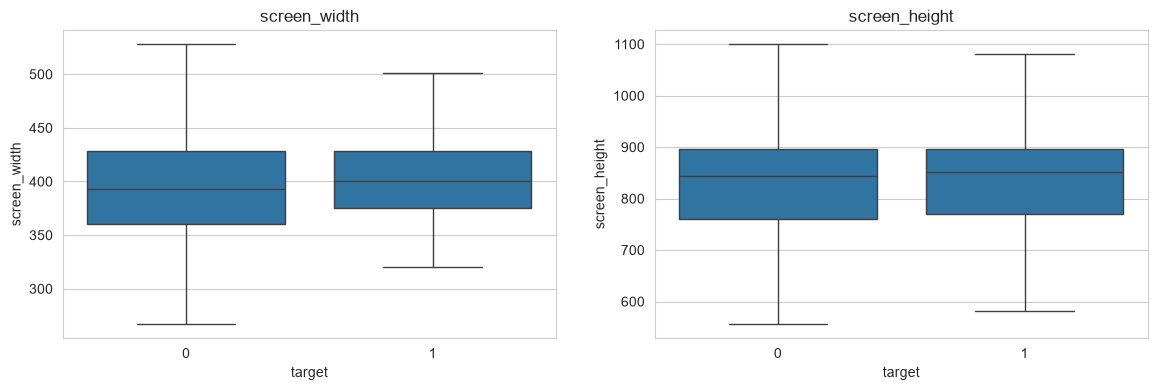

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['screen_width', 'screen_height']):
    sns.boxplot(x='target', y=col, data=df, ax=ax, showfliers=False)
    ax.set_title(col)
plt.show()

## 5. Correlations

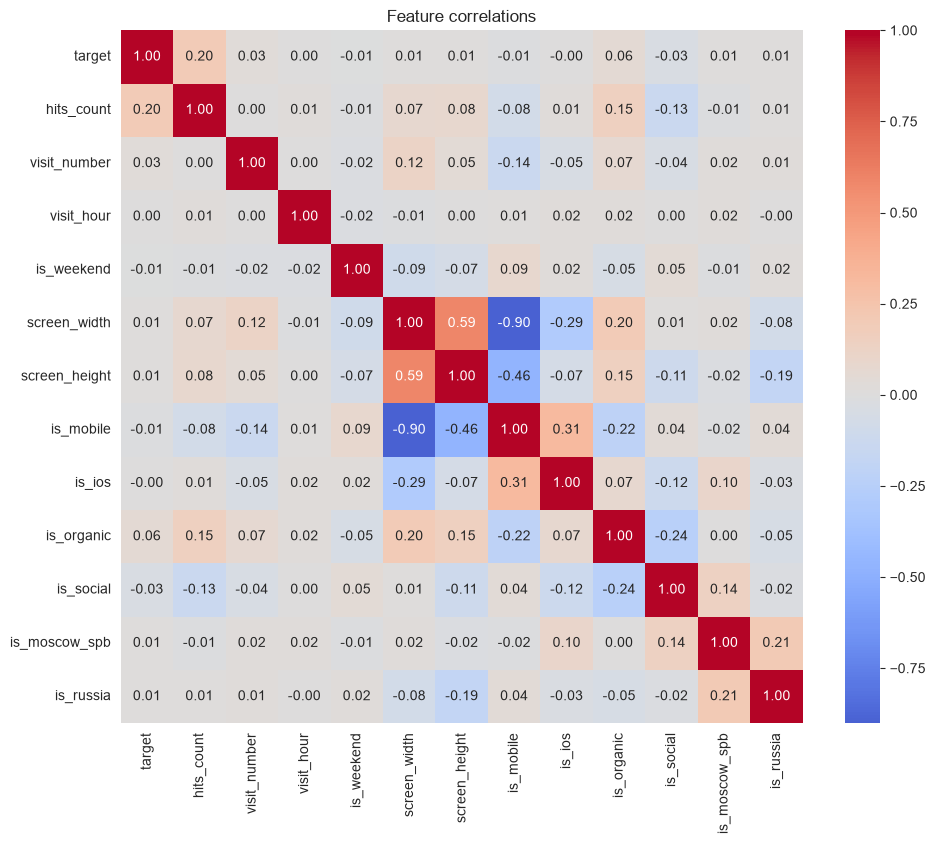

In [29]:
df['is_mobile'] = (df['device_category'] == 'mobile').astype(int)
df['is_ios'] = (df['device_os'] == 'iOS').astype(int)
df['is_weekend'] = (df['visit_weekday'] >= 5).astype(int)

corr_cols = ['target', 'hits_count', 'visit_number', 'visit_hour', 'is_weekend', 'screen_width', 'screen_height',
             'is_mobile', 'is_ios', 'is_organic', 'is_social', 'is_moscow_spb', 'is_russia']
corr = df[corr_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlations')
plt.show()

In [30]:
corr['target'].drop('target').sort_values(key=abs, ascending=False).round(3)

hits_count       0.202
is_organic       0.056
is_social       -0.033
visit_number     0.028
is_mobile       -0.012
screen_height    0.010
is_weekend      -0.009
screen_width     0.007
is_russia        0.006
is_moscow_spb    0.006
is_ios          -0.001
visit_hour       0.000
Name: target, dtype: float64

hits_count has the highest correlation with the target (0.20), but it's known only after the visit, so it can't go into the model. Of the usable ones is_organic is 0.06, visit_number 0.03, is_social -0.03, all weak. is_mobile and screen width are strongly linked (-0.90), width and height 0.59. The link with the categories is not linear (see the CR plots), so a tree model should work better than a linear one.

## 6. Saving

In [31]:
df.drop(columns=['visit_time']).to_pickle('data/sessions_clean.pkl')
print(df.shape)

(1732266, 30)


## Conclusions

- 1,732,266 visits after the join (May to December 2021), 2.9% with a target action, the classes are imbalanced so the metric is ROC-AUC.
- Cleaning: '(not set)' as missing, device_model dropped, device_os restored from the brand, the rest filled with 'other', 127,776 visits without events removed.
- Visits jump on 24 May (launch) and 20 December, conversion goes down from 4-8% at the start to about 2% at the end of the year.
- Organic 4.4% vs paid 2.3%, referral is the best (6.0%), cpm (1.1%) and social ads (1.6%) the worst.
- Desktop 3.3%, mobile 2.8%, tablet 2.5%. Safari in-app only 1.9%.
- Daytime and Monday (3.4%) are better, Friday and the weekend around 2.6%.
- First visit 2.5%, from the 4th visit about 5%.
- Moscow 3.2%, SPb 2.6%, Kazan 4.1%.

The cleaned table is saved to `data/sessions_clean.pkl`. For the model the same cleaning is in a function in `02_model.ipynb` and `pipeline.py`, since the service gets raw rows.